In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_excel("Online Retail.xlsx")

# Display first 5 records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Column information
print("\nDataset Information:")
df.info()

# 3. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 5. Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# 6. Unique customers
print("\nUnique Customers:", df['CustomerID'].nunique())

# 7. Unique countries
print("\nCountries:", df['Country'].nunique())

Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



Unique Customers: 4372

Countries: 38


In [ ]:
# Create a copy of original dataset
df_clean = df.copy()

# Store original row count
original_rows = len(df_clean)

# 1. Remove missing CustomerID
df_clean = df_clean.dropna(subset=['CustomerID'])

# 2. Remove duplicate records
df_clean = df_clean.drop_duplicates()

# 3. Remove cancelled invoices
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# 4. Remove negative or zero quantities
df_clean = df_clean[df_clean['Quantity'] > 0]

# 5. Remove zero or negative prices
df_clean = df_clean[df_clean['UnitPrice'] > 0]

# 6. Convert CustomerID into integer
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# 7. Calculate total purchase value
df_clean['TotalPrice'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

# Display cleaning results
print("Original Rows:", original_rows)
print("Cleaned Rows:", len(df_clean))
print("Rows Removed:", original_rows - len(df_clean))

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows After Cleaning:",
      df_clean.duplicated().sum())

print("\nCleaned Dataset Shape:", df_clean.shape)

display(df_clean.head())

Original Rows: 541909
Cleaned Rows: 392692
Rows Removed: 149217

Missing Values After Cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

Duplicate Rows After Cleaning: 0

Cleaned Dataset Shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [ ]:
# Set analysis date
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

print("RFM Dataset Shape:", rfm.shape)

display(rfm.head(10))

RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40


In [ ]:
print("RFM Descriptive Statistics")

display(rfm.describe())

print("\nAverage Recency:", rfm['Recency'].mean())
print("Average Frequency:", rfm['Frequency'].mean())
print("Average Monetary:", rfm['Monetary'].mean())

RFM Descriptive Statistics


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000



Average Recency: 92.53642231443061
Average Frequency: 4.272014753342554
Average Monetary: 2048.688080682342


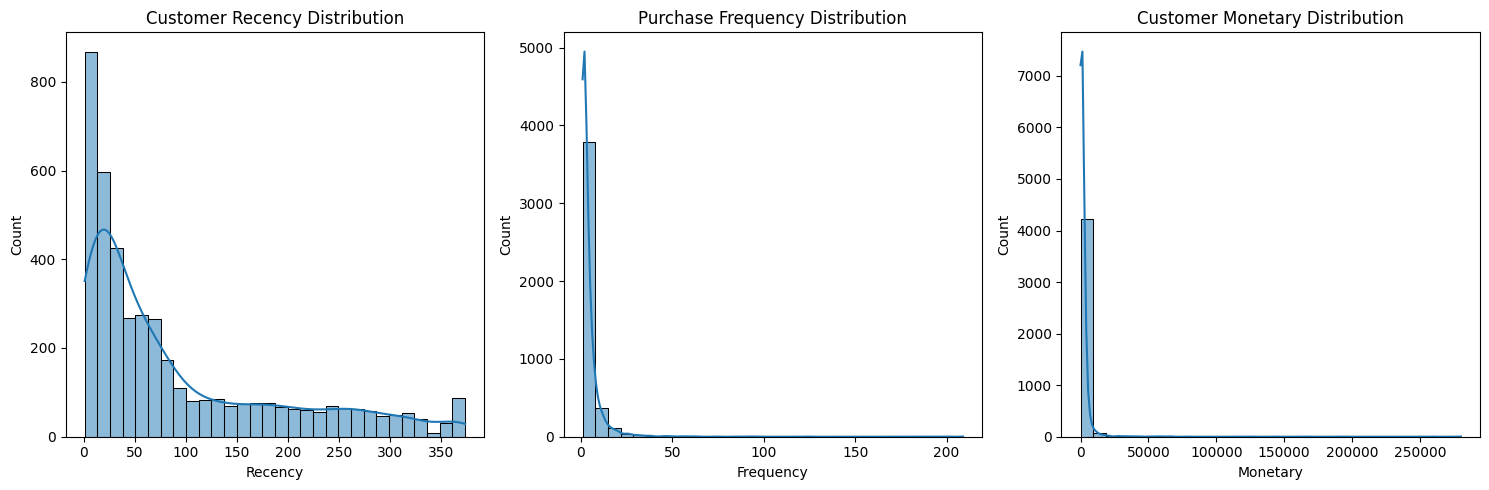

In [ ]:
# Visualize RFM distributions

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=30, kde=True)
plt.title('Customer Recency Distribution')

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=30, kde=True)
plt.title('Purchase Frequency Distribution')

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=30, kde=True)
plt.title('Customer Monetary Distribution')

plt.tight_layout()
plt.show()

In [ ]:
# Standardize RFM features

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

# Convert back to DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

print("Scaled RFM Dataset:")
display(rfm_scaled.head())

print("\nScaled Feature Means:")
print(rfm_scaled.mean().round(2))

print("\nScaled Feature Standard Deviations:")
print(rfm_scaled.std().round(2))

Scaled RFM Dataset:


,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.363010
12347,-0.905340,0.354417,0.251699
12348,-0.175360,-0.035340,-0.027988
12349,-0.735345,-0.425097,-0.032406
12350,2.174578,-0.425097,-0.190812



Scaled Feature Means:
Recency      0.0
Frequency    0.0
Monetary     0.0
dtype: float64

Scaled Feature Standard Deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


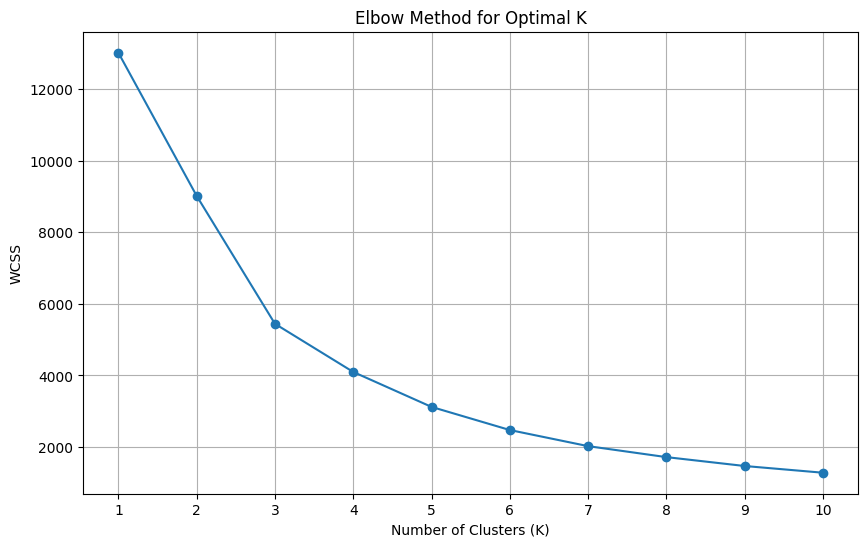

In [ ]:
# Calculate WCSS for different cluster numbers

wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Curve

plt.figure(figsize=(10, 6))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [ ]:
# Train the K-Means model

kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Assign clusters to customers
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display results
print("K-Means Clustering Completed!")

print("\nCustomer Cluster Assignments:")
display(rfm.head(10))

print("\nNumber of Customers in Each Cluster:")
print(rfm['Cluster'].value_counts().sort_index())

K-Means Clustering Completed!

Customer Cluster Assignments:


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,0
12347,2,7,4310.00,1
12348,75,4,1797.24,1
12349,19,1,1757.55,1
12350,310,1,334.40,0
12352,36,8,2506.04,1
12353,204,1,89.00,0
12354,232,1,1079.40,0
12355,214,1,459.40,0



Number of Customers in Each Cluster:
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64


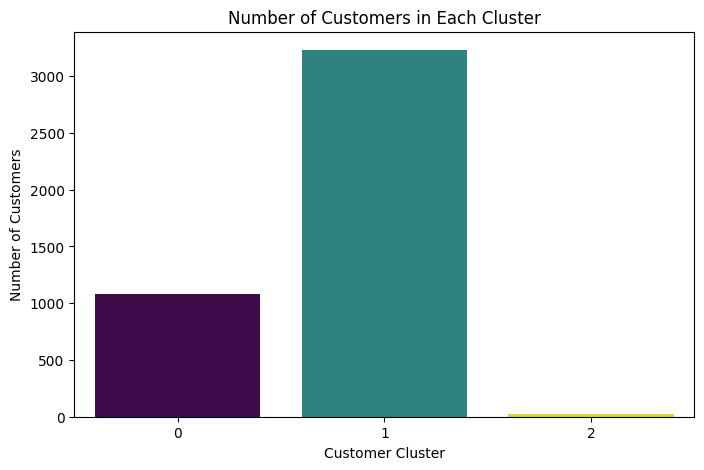

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

cluster_profile['Customer_Count'] = rfm.groupby('Cluster').size()

display(cluster_profile)

,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,247.11,1.58,629.66,1082
1,41.45,4.67,1849.67,3230
2,6.04,66.42,85826.08,26


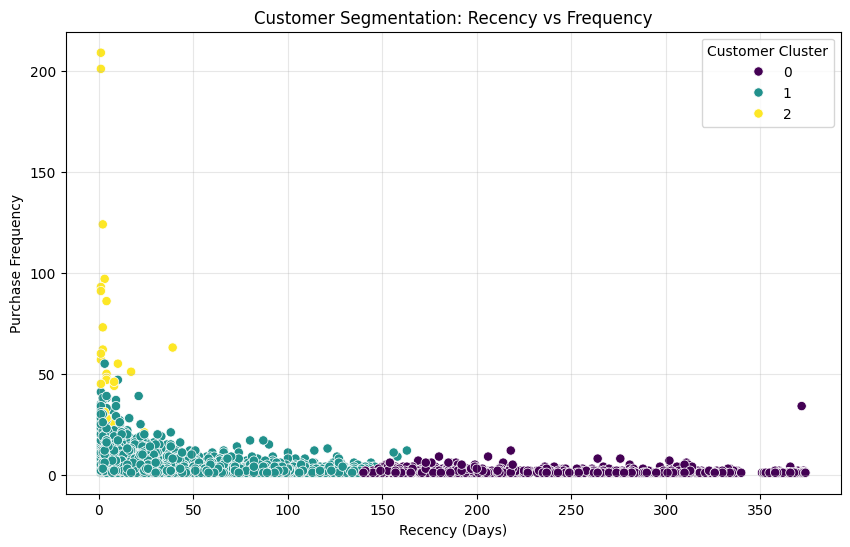

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis',
    s=45
)

plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')
plt.legend(title='Customer Cluster')
plt.grid(alpha=0.3)
plt.show()

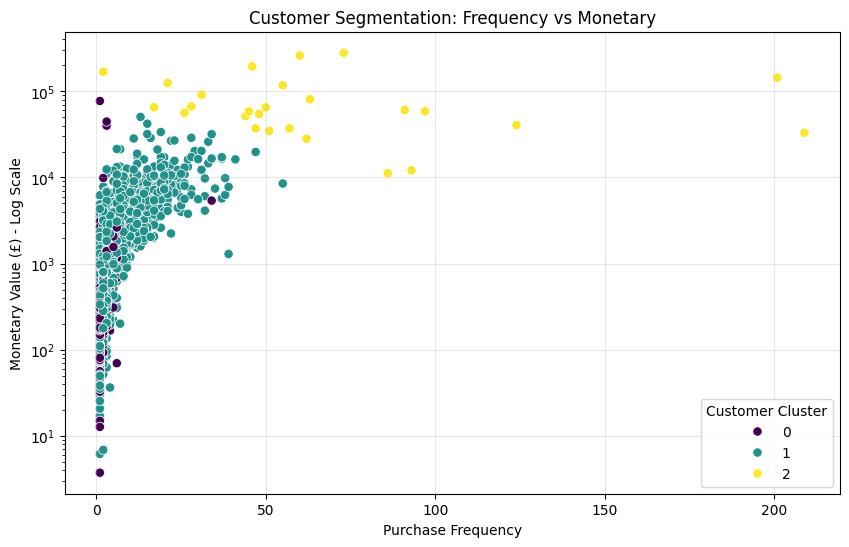

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=45
)

plt.yscale('log')

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Monetary Value (£) - Log Scale')
plt.legend(title='Customer Cluster')
plt.grid(alpha=0.3)
plt.show()

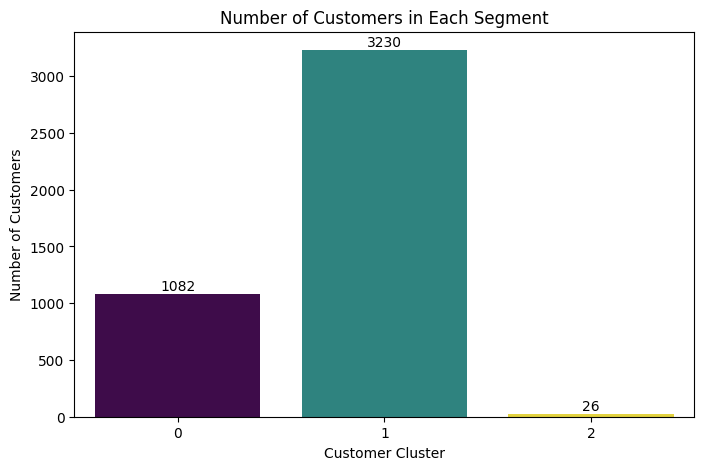

In [ ]:
plt.figure(figsize=(8, 5))

cluster_counts = rfm['Cluster'].value_counts().sort_index()

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values,
    hue=cluster_counts.index,
    palette='viridis',
    legend=False
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

for i, value in enumerate(cluster_counts.values):
    plt.text(i, value + 30, str(value), ha='center')


plt.show()

## Business Insights and Marketing Recommendations

Based on the K-Means clustering algorithm, customers were divided into three distinct segments using Recency, Frequency and Monetary (RFM) values.

### Cluster 0 – At-Risk / Inactive Customers
- Customer count: 1,082
- Average Recency: 247.11 days
- Average Frequency: 1.58 purchases
- Average Monetary Value: £629.66

**Insight:** These customers have not purchased recently and demonstrate low purchasing frequency.

**Marketing Recommendation:** Implement re-engagement campaigns, personalised discounts and reminder emails to encourage repeat purchases.

### Cluster 1 – Regular Customers
- Customer count: 3,230
- Average Recency: 41.45 days
- Average Frequency: 4.67 purchases
- Average Monetary Value: £1,849.67

**Insight:** This is the largest customer segment. These customers purchase relatively frequently and have comparatively recent activity.

**Marketing Recommendation:** Introduce loyalty programmes, product recommendations, cross-selling and personalised promotions to improve retention.

### Cluster 2 – High-Value VIP Customers
- Customer count: 26
- Average Recency: 6.04 days
- Average Frequency: 66.42 purchases
- Average Monetary Value: £85,826.08

**Insight:** This small customer segment demonstrates exceptionally high purchase frequency and monetary value.

**Marketing Recommendation:** Provide exclusive rewards, premium customer support, early access to new products and personalised VIP offers.

### Overall Business Findings

1. The majority of customers belong to Cluster 1, representing the regular customer segment.
2. Cluster 0 presents an opportunity for customer reactivation.
3. Cluster 2 represents a small but exceptionally valuable customer group that deserves special attention.
4. RFM-based clustering enables businesses to design targeted marketing strategies instead of treating all customers identically.

In [ ]:
# Export customer segmentation results

rfm.to_csv(
    'Customer_Segmentation_Results.csv',
    index=True
)

cluster_profile.to_csv(
    'Customer_Cluster_Profile.csv'
)

print("Files exported successfully!")

print("1. Customer_Segmentation_Results.csv")
print("2. Customer_Cluster_Profile.csv")

Files exported successfully!
1. Customer_Segmentation_Results.csv
2. Customer_Cluster_Profile.csv


In [ ]:
print("FINAL PROJECT VERIFICATION")

print("\nTotal Customers:", len(rfm))

print("\nNumber of Clusters:", rfm['Cluster'].nunique())

print("\nCluster Distribution:")
print(rfm['Cluster'].value_counts().sort_index())

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nDuplicate Customers:", rfm.index.duplicated().sum())

print("\nExport Verification:")
import os

print(os.listdir('/content'))

FINAL PROJECT VERIFICATION

Total Customers: 4338

Number of Clusters: 3

Cluster Distribution:
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64

Missing Values:
Recency      0
Frequency    0
Monetary     0
Cluster      0
dtype: int64

Duplicate Customers: 0

Export Verification:
['.config', 'Customer_Cluster_Profile.csv', 'Online Retail.xlsx', 'Customer_Segmentation_Results.csv', 'sample_data']


In [ ]:
plt.savefig('filename.png', dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import os

# Create visualizations folder
os.makedirs('/content/visualizations', exist_ok=True)

# Save all currently available figures
for i, fig in enumerate(plt.get_fignums(), start=1):
    fig_obj = plt.figure(fig)
    fig_obj.savefig(
        f'/content/visualizations/figure_{i}.png',
        dpi=300,
        bbox_inches='tight'
    )

print("All available figures saved successfully!")
print(os.listdir('/content/visualizations'))

All available figures saved successfully!
[]


In [22]:
import shutil
from google.colab import files

shutil.make_archive(
    '/content/visualizations',
    'zip',
    '/content/visualizations'
)

files.download('/content/visualizations.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('/content/visualizations', exist_ok=True)

# 1. RFM Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm[col], bins=30, kde=True, ax=ax)
    ax.set_title(f'{col} Distribution')

plt.tight_layout()
fig.savefig('/content/visualizations/rfm_distributions.png', dpi=300)
plt.close(fig)

# 2. Elbow Method
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, 11), wcss, marker='o')
ax.set_title('Elbow Method for Optimal K')
ax.set_xlabel('Number of Clusters')
ax.set_ylabel('WCSS')
ax.grid(True)
fig.savefig('/content/visualizations/elbow_method.png', dpi=300)
plt.close(fig)

# 3. Cluster Distribution
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=rfm, x='Cluster', hue='Cluster',
              palette='viridis', legend=False, ax=ax)
ax.set_title('Number of Customers in Each Cluster')
fig.savefig('/content/visualizations/cluster_distribution.png', dpi=300)
plt.close(fig)

# 4. Recency vs Frequency
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=rfm, x='Recency', y='Frequency',
                hue='Cluster', palette='viridis', ax=ax)
ax.set_title('Recency vs Frequency')
fig.savefig('/content/visualizations/recency_frequency.png', dpi=300)
plt.close(fig)

# 5. Frequency vs Monetary
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=rfm, x='Frequency', y='Monetary',
                hue='Cluster', palette='viridis', ax=ax)
ax.set_yscale('log')
ax.set_title('Frequency vs Monetary')
fig.savefig('/content/visualizations/frequency_monetary.png', dpi=300)
plt.close(fig)

print("Saved files:", os.listdir('/content/visualizations'))

Saved files: ['recency_frequency.png', 'rfm_distributions.png', 'cluster_distribution.png', 'elbow_method.png', 'frequency_monetary.png']


In [24]:
import shutil
from google.colab import files

shutil.make_archive(
    '/content/visualizations',
    'zip',
    '/content/visualizations'
)

files.download('/content/visualizations.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>